In [1]:
import os
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# 1. Load the CSV file
filename = "time_schedule_10-19_to_10-25.csv"
df = pd.read_csv(filename, index_col=0)

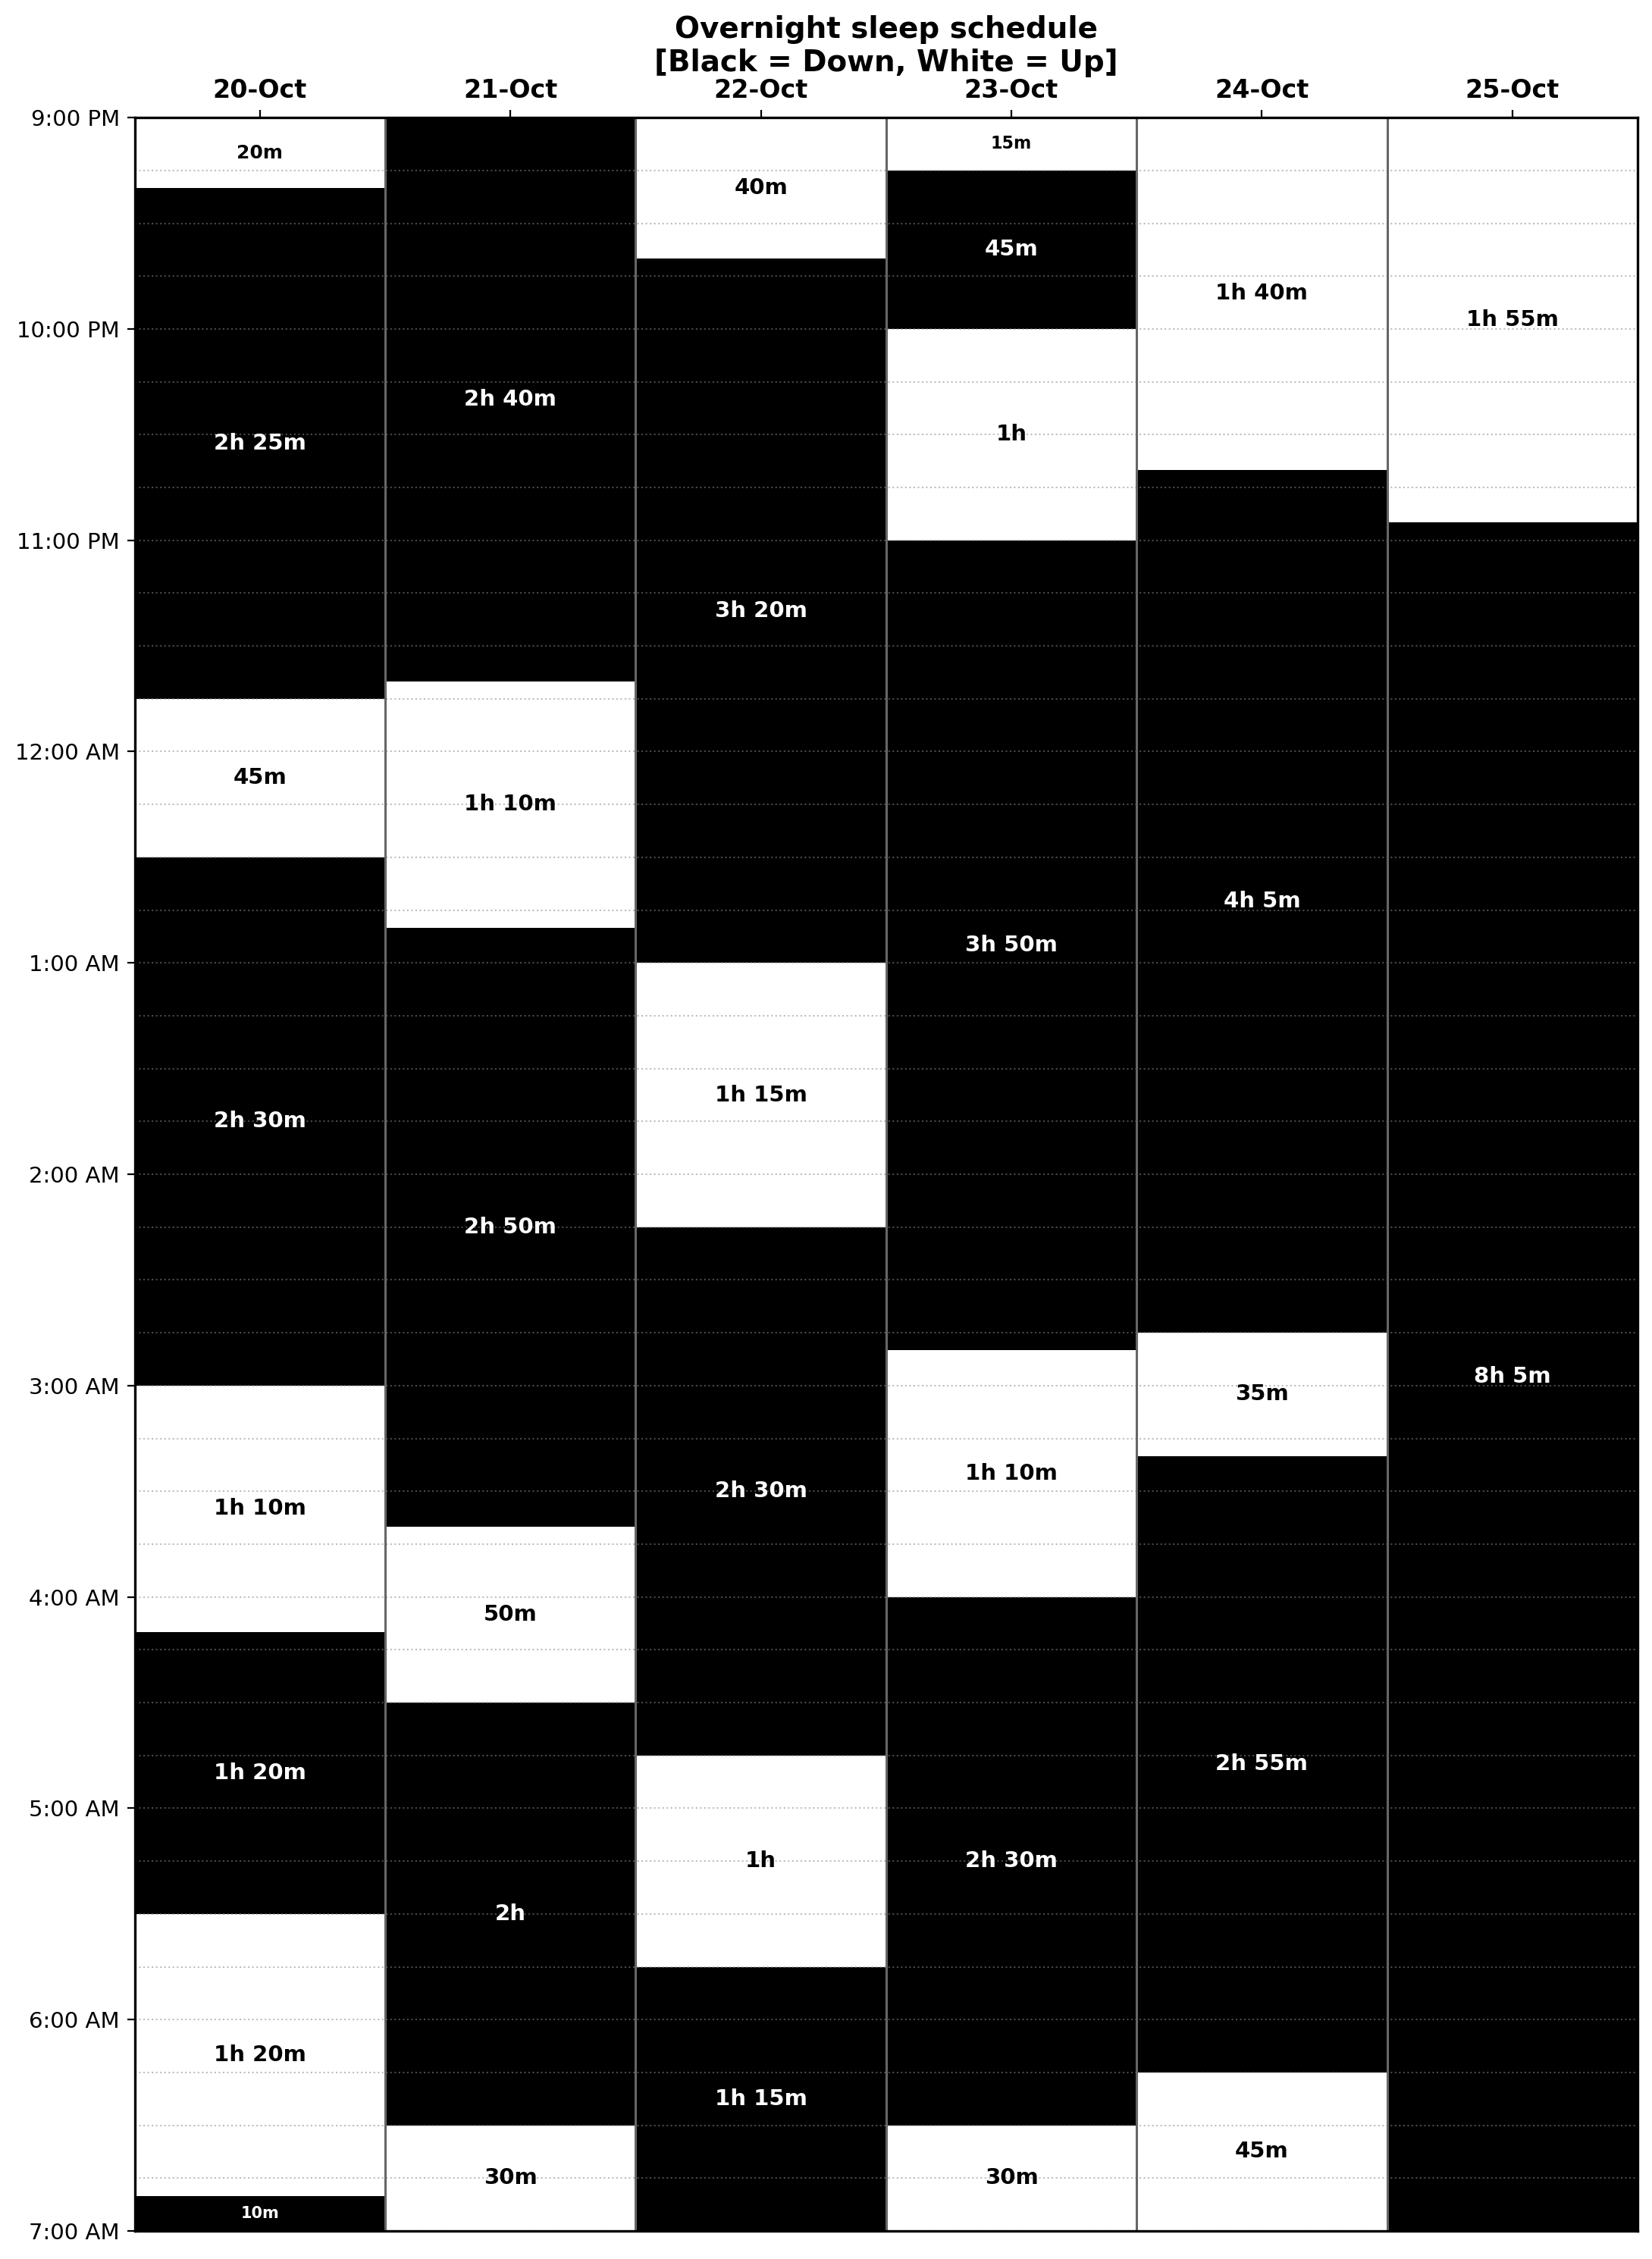

In [5]:
# 2. Map row indices to minute offsets (9:00 PM = 0 min, 7:00 AM = 600 min)
time_to_min = {t: i * 5 for i, t in enumerate(df.index)}

# 3. Parse continuous time blocks for each date column
blocks_by_col = {}
for col in df.columns:
    events = []
    col_data = df[col].dropna()
    for t, val in col_data.items():
        state_str = str(val).strip().lower()
        if state_str in ["up", "down"]:
            events.append((time_to_min[t], state_str))

    events.sort(key=lambda x: x[0])

    blocks = []
    current_time = 0
    current_state = "up"  # Default starting state before first event

    for ev_time, ev_state in events:
        if ev_time == 0:
            current_state = ev_state
        elif ev_time > current_time:
            dur = ev_time - current_time
            blocks.append((current_state, current_time, ev_time, dur))
            current_time = ev_time
            current_state = ev_state
        elif ev_time == current_time:
            current_state = ev_state

    # Extend final state to 7:00 AM (600 minutes)
    if current_time < 600:
        blocks.append((current_state, current_time, 600, 600 - current_time))

    blocks_by_col[col] = blocks

# 4. Generate Visualization
fig, ax = plt.subplots(figsize=(11, 15), dpi=200)

columns = list(df.columns)
n_cols = len(columns)

# Draw blocks and duration text labels
for col_idx, col in enumerate(columns):
    for state, t_start, t_end, dur in blocks_by_col[col]:
        facecolor = "black" if state == "down" else "white"
        textcolor = "white" if state == "down" else "black"

        # Block rectangle
        rect = patches.Rectangle(
            (col_idx - 0.5, t_start),
            1.0,
            dur,
            facecolor=facecolor,
            edgecolor="none",
            zorder=1,
        )
        ax.add_patch(rect)

        # Center vertically in the block
        center_y = t_start + dur / 2.0

        # Format duration label (e.g., '2h 25m', '45m', '1h')
        h, m = divmod(dur, 60)
        if h > 0 and m > 0:
            dur_str = f"{h}h {m}m"
        elif h > 0:
            dur_str = f"{h}h"
        else:
            dur_str = f"{m}m"

        # Dynamically scale font size for narrower time blocks
        if dur >= 30:
            fontsize = 10.5
        elif dur >= 20:
            fontsize = 9.0
        elif dur >= 15:
            fontsize = 8.0
        else:
            fontsize = 7.5

        ax.text(
            col_idx,
            center_y,
            dur_str,
            color=textcolor,
            ha="center",
            va="center",
            fontweight="bold",
            fontsize=fontsize,
            zorder=3,
        )

# Dotted gray horizontal lines every 15 minutes
for t in range(0, 601, 15):
    ax.axhline(
        t, color="#888888", linestyle=":", linewidth=0.75, alpha=0.55, zorder=2
    )

# Solid vertical borders between columns
for x in np.arange(0.5, n_cols - 0.5, 1):
    ax.axvline(x, color="#666666", linewidth=1.1, linestyle="-", zorder=2)

# Axis configuration
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(
    600, 0
)  # Invert Y-axis so 9:00 PM (0 min) is at top and 7:00 AM (600 min) is at bottom

# X-axis ticks (Dates)
ax.set_xticks(range(n_cols))
ax.set_xticklabels(columns, fontsize=12, fontweight="bold")
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Y-axis ticks (Hourly labels)
hourly_ticks = list(range(0, 601, 60))
hourly_labels = [
    "9:00 PM",
    "10:00 PM",
    "11:00 PM",
    "12:00 AM",
    "1:00 AM",
    "2:00 AM",
    "3:00 AM",
    "4:00 AM",
    "5:00 AM",
    "6:00 AM",
    "7:00 AM",
]
ax.set_yticks(hourly_ticks)
ax.set_yticklabels(hourly_labels, fontsize=10.5, fontweight="medium")

# Outer chart border
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

ax.set_title(
    "Overnight sleep schedule\n[Black = Down, White = Up]",
    fontsize=14,
    pad=22,
    fontweight="bold",
)

plt.tight_layout()
plt.savefig("schedule_durations_visualization.png", dpi=200, bbox_inches="tight")
plt.show()